# EJERCICIO 2: Minimización del consumo energético urbano

Enunciado
Una ciudad quiere reducir su consumo energético redistribuyendo la carga entre distintos sectores (residencial, comercial, industrial).

Debes encontrar la mejor combinación de reducción de consumo por sector que minimice el consumo total sin reducir el servicio por debajo de un umbral mínimo.

Variables
* Genotipo: vector [Reducción_R, Reducción_C, Reducción_I] (en %)
* Fitness: consumo total minimizado
* Restricciones: servicios ≥ 90% del mínimo requerido

Experimentación
* Selección: torneo vs por ranking
* Mutación: gaussiana (pequeño cambio en %)

Prueba con:
* Diversidad alta (mutación alta)
* Diversidad baja (elitismo fuerte)

Evaluaciones
* Frontera de soluciones (eficiencia vs impacto)
* Convergencia del consumo total

In [29]:
%pip install PyGAD

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [30]:
# Solución utilizando librería PyGAD
import pygad
import pygad.nn
import pygad.gann
import numpy as np
import matplotlib.pyplot as plt

In [31]:
# Supuestos: Reducción en % por sector (residencial, comercial, industrial)
# Reducción máxima por sector = 30%, mínima = 0%

# Consumo actual en kWh por sector (ficticios)
sector_names = ['Residencial', 'Comercial', 'Industrial']
base_consumo = np.array([800, 1000, 1200])
servicio_minimo = base_consumo * 0.9

In [32]:
# Función objetivo: minimizar el consumo total penalizando si bajamos de mínimo
def fitness_func(ga_instance, solution, solution_idx):
    consumo = base_consumo * (1 - solution / 100.0)
    penalidad = np.sum(consumo < servicio_minimo) * 1e6  # penaliza muy fuerte si se incumple
    return -np.sum(consumo) - penalidad  # minimizar el consumo total

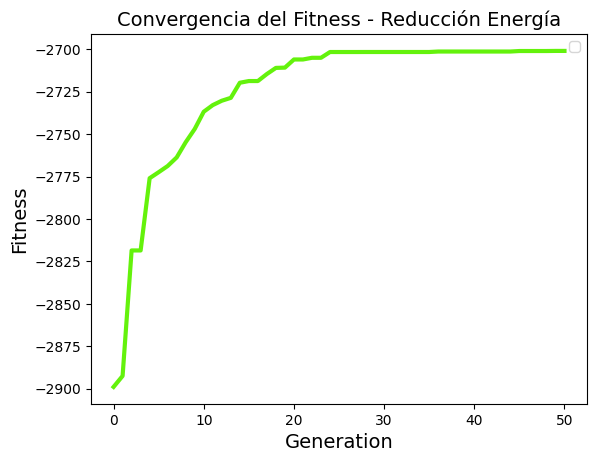

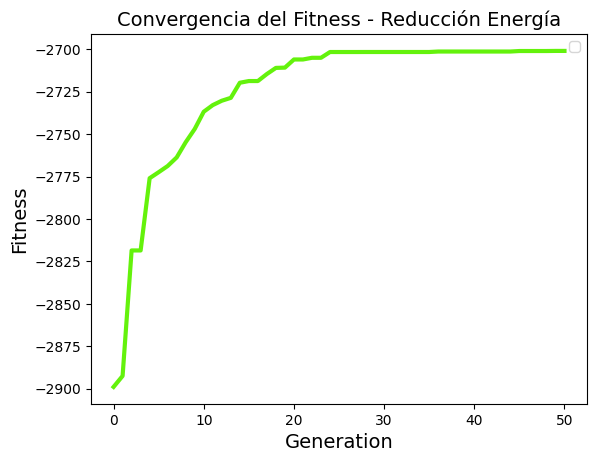

In [33]:
# Configuración del GA
ga_instance = pygad.GA(
    num_generations=50,
    num_parents_mating=10,
    fitness_func=fitness_func,
    sol_per_pop=20,
    num_genes=3,
    init_range_low=0,
    init_range_high=30,
    parent_selection_type="tournament",
    keep_parents=2,
    crossover_type="single_point",
    mutation_type="random",
    mutation_percent_genes=30
)

ga_instance.run()

ga_instance.plot_fitness(title="Convergencia del Fitness - Reducción Energía")

In [34]:
# Mejor solución
solution, solution_fitness, _ = ga_instance.best_solution()
print("Mejor reducción por sector (%):", solution)
print("Consumo total resultante:", np.sum(base_consumo * (1 - solution / 100.0)))

Mejor reducción por sector (%): [9.96346033 9.66621721 9.99132213]
Consumo total resultante: 2703.7342797025353


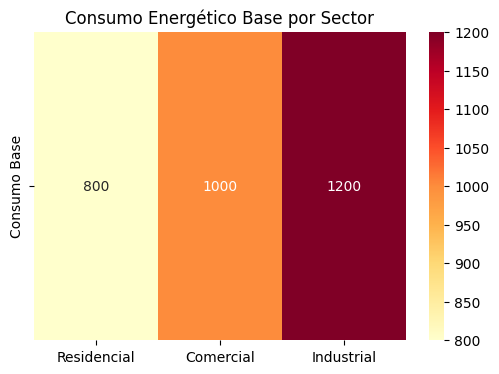

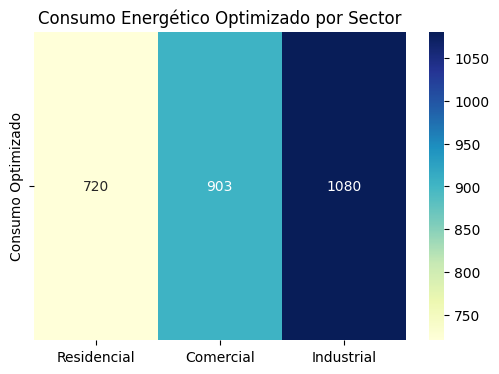

In [35]:
# Visualización de matriz de calor
import seaborn as sns
plt.figure(figsize=(6, 4))
sns.heatmap(base_consumo.reshape(1, -1), annot=True, fmt='.0f', cmap="YlOrRd", xticklabels=sector_names, yticklabels=["Consumo Base"])
plt.title("Consumo Energético Base por Sector")
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap((base_consumo * (1 - solution/100.0)).reshape(1, -1), annot=True, fmt='.0f', cmap="YlGnBu", xticklabels=sector_names, yticklabels=["Consumo Optimizado"])
plt.title("Consumo Energético Optimizado por Sector")
plt.show()